In [1]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt

from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets
from IPython.display import display, Math
from numpyarray_to_latex.jupyter import to_ltx


import torch


def pprint(*args):
    res = ""
    for i in args:
        if type(i) == np.ndarray:
            res += to_ltx(i, brackets="[]")
        elif type(i) == torch.Tensor:
            res += to_ltx(
                i.detach().cpu().numpy(),
                brackets="[]",
            )
        else:
            res += str(i)
    display(Math(res))



## library


### numpy


In [2]:
a1 = np.arange(0, 3, 0.4)
pprint("coucou", a1)
print(np.sum(a1))


<IPython.core.display.Math object>

11.200000000000001


In [3]:
population = np.array([1, 2, 3, 4, 5])
s = np.random.choice(population, size=(3, 3), replace=True)
pprint("s=", s)


<IPython.core.display.Math object>

### scipy


In [4]:
mu, sigma = 0, 1
pprint("pdf=", sp.stats.norm.pdf(1, loc=mu, scale=sigma))
pprint("s=", sp.stats.norm.ppf(np.array([0.25, 0.50, 0.75]), loc=mu, scale=sigma))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

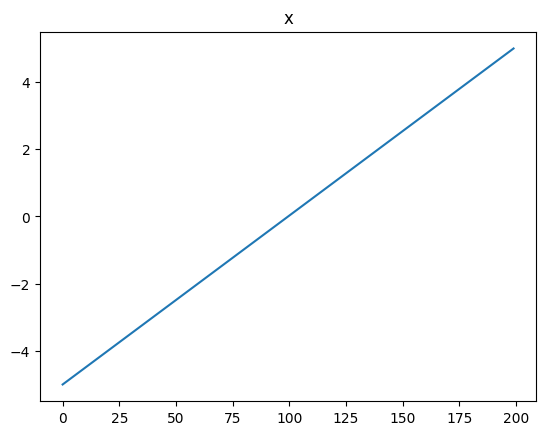

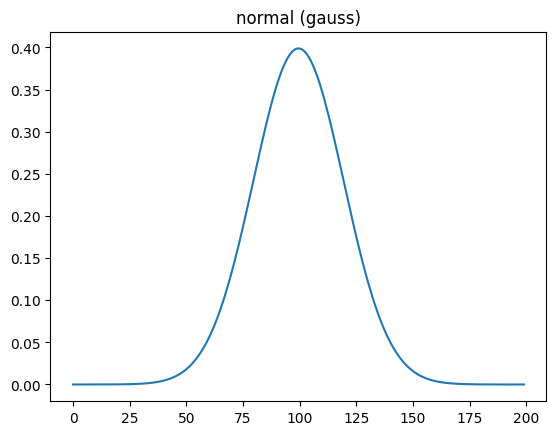

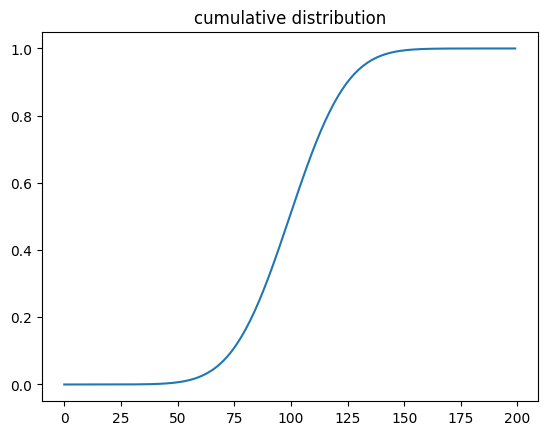

In [5]:
n_bins = 100
x = np.linspace(-5, 5, 200)  # 200 elemest from start to end
y = sp.stats.norm.pdf(x, loc=mu, scale=sigma)
c = sp.stats.norm.cdf(x, loc=mu, scale=sigma)
qs = sp.stats.norm.ppf(np.array([0.25, 0.50, 0.75]), loc=mu, scale=sigma)
plt.plot(x)
plt.title("x")
plt.show()
plt.plot(y)
plt.title("normal (gauss)")
plt.show()
plt.plot(c)
plt.title("cumulative distribution")
plt.show()


def prob_dens_normal(mu, sig):
    y = sp.stats.norm.pdf(
        x, loc=mu, scale=sig
    )  # give a normal distribution for each element of x
    c = sp.stats.norm.cdf(x, loc=mu, scale=sig)
    qs = sp.stats.norm.ppf(np.array([0.25, 0.50, 0.75]), loc=mu, scale=sig)
    plt.figure(figsize=(10, 5))
    plt.plot(x, s)
    plt.hist(np.random.normal(size=(25000,)), bins=n_bins, density=True)
    for q in qs:
        plt.vlines(q, 0, 0.5)
    plt.title("probability density function of a N(0,1)")
    plt.show()


interact(prob_dens_mu=(-50, 50), sig=(50))


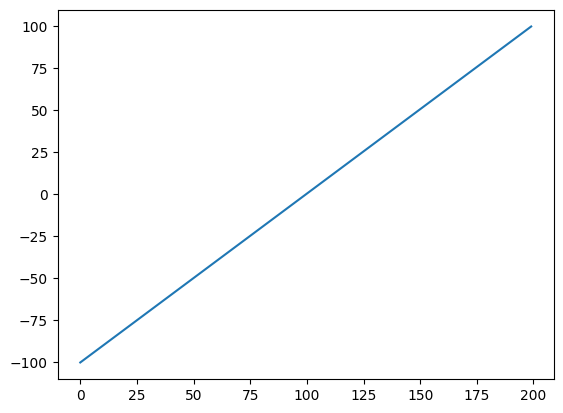

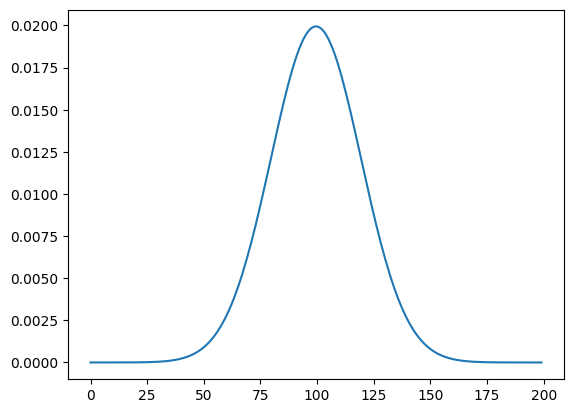

interactive(children=(IntSlider(value=0, description='mu', min=-100), IntSlider(value=25, description='sig', m…

<function __main__.test_normal(mu, sig)>

In [6]:
x = np.linspace(-100, 100, 200)
plt.show()
plt.plot(x)
plt.show()
y = sp.stats.norm.pdf(x, 0, 20)
plt.plot(y)
plt.show()


def test_normal(mu, sig):
    y = sp.stats.norm.pdf(x, mu, sig)
    plt.figure(figsize=(10, 5))
    plt.plot(y)
    plt.show()


interact(test_normal, mu=(-100, 100), sig=(0, 50))


## Neural networks


### Tensors


In [7]:
import torch


In [8]:
# Create a 2-D tensor (matrix) for demonstration
x = torch.tensor([[10, 11, 12], [20, 21, 22], [30, 31, 32]])
pprint("\\text{Original tensor: }", x)

# Indexing a single element
pprint(
    "\\text{Element at (0, 1): }", str(x[0, 1].item())
)  # .item() to get Python scalar

# Slicing rows and columns
pprint("\\text{First row: }", x[0])  # equivalent to x[0, :]
pprint("\\text{Last column: }", x[:, -1])  # all rows, last column

# Slice a submatrix (e.g., top-left 2x2 block)
sub_x = x[0:2, 0:2]  # rows 0-1 and cols 0-1
pprint("\\text{Top-left 2x2 sub-tensor: }", sub_x)

# Modify part of the tensor
x[1:, 1:] = torch.tensor(
    [[-1, -2], [-3, -4]]
)  # set bottom-right 2x2 block to new values
pprint("\\text{Tensor after modification: }", x)


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [9]:
# Reshape (view) a tensor
t = torch.arange(16)  # 1-D tensor [0, 1, 2, ..., 15]
pprint("t=", t)

t_matrix = t.reshape(4, 4)  # reshape to 4x4 matrix
pprint("\\text{t reshaped to 4x4: }", t_matrix)

# Transpose the matrix (swap dimensions)
pprint("t^T: ", t_matrix.T)


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [10]:
t = torch.arange(16)
pprint("t=", t)
t_matrix = t.reshape(8, 2)
pprint("\\text{t=}", t_matrix)


<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [11]:
t1 = torch.arange(6).reshape(2, 3)
t2 = torch.arange(6, 12).reshape(2, 3)
pprint(t1, t2)
t_cat0 = torch.cat([t1, t2], dim=0)
pprint("\\text{cat dim0=}", t_cat0)
t_cat1 = torch.cat([t1, t2], dim=1)
pprint("t2=", t_cat1)


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

#### autograd
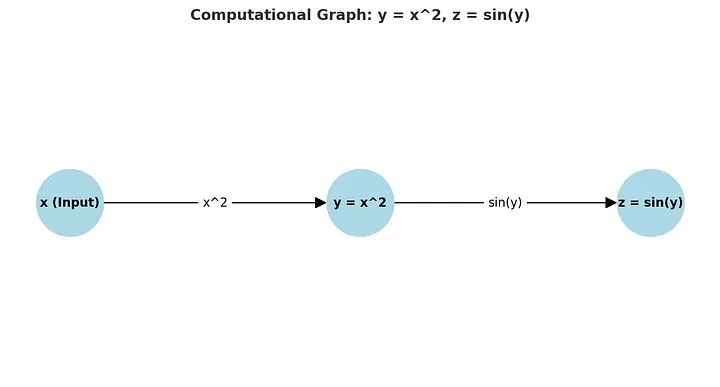


In [12]:
x = torch.tensor(3.0, requires_grad=True)
print("x:", x)

y = x**2 + 2 * x + 1
print("y:", y)
print(x.grad)
y.backward()
print("dy/dx at x=3:", x.grad)


x: tensor(3., requires_grad=True)
y: tensor(16., grad_fn=<AddBackward0>)
None
dy/dx at x=3: tensor(8.)


In [20]:
# Autograd with two inputs: z = x * y + y^2
x = torch.tensor(2.0, requires_grad=True)
y = torch.tensor(-3.0, requires_grad=True)

z = x * y + y**2  # z is a function of both x and y
print("z:", z)

z.backward()  # Compute gradients dz/dx and dz/dy
print("dz/dx:", x.grad)  # should be y
print("dz/dy:", y.grad)  # should be x + 2y


z: tensor(3., grad_fn=<AddBackward0>)
dz/dx: tensor(-3.)
dz/dy: tensor(-4.)


#### in-place operation
adding a suffix at the end of a method make it not copy the resulting tensor.


In [14]:
a = torch.ones(5)
pprint("a=", a)

# Out-of-place addition
b = a.add(5)
print("After b = a.add(5):")
pprint("a=", a)  # a should remain unchanged
pprint("b=", b)  # b is the new tensor

# In-place addition
a.add_(5)
print("\nAfter a.add_(5):")
pprint("a=", a)  # a is now changed in-place

<IPython.core.display.Math object>

After b = a.add(5):


<IPython.core.display.Math object>

<IPython.core.display.Math object>


After a.add_(5):


<IPython.core.display.Math object>